<a href="https://colab.research.google.com/github/Lowei1225/AI/blob/main/keras_CNN_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

# 建立模型
model=Sequential()

# 卷積層：擷取圖片特徵
model.add(Conv2D(filters=16, kernel_size=(5, 5), input_shape=(28, 28, 1), activation='relu'))

# 池化層：縮小圖片
model.add(MaxPooling2D(pool_size=(2, 2)))

# 第二層卷積與池化（暫時不使用）
#model.add(Conv2D(filters=36, kernel_size=(5, 5), activation='relu'))
#model.add(MaxPooling2D(pool_size=(2, 2)))

# 將資料展平成一維
model.add(Flatten())

# 輸出10種數字分類
model.add(Dense(10, activation='softmax'))

# 顯示模型架構
model.summary()

# 設定模型
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,466 (91.66 KB)

 Trainable params: 23,466 (91.66 KB)

 Non-trainable params: 0 (0.00 B)

In [2]:
# 載入 MNIST 手寫數字資料
mnist=keras.datasets.mnist
(train_data, train_label), (test_data, test_label) = mnist.load_data()

# 保留原始答案
test_label_original=test_label

# 將標籤轉成 One-hot 編碼
train_label = keras.utils.to_categorical(train_label)
test_label = keras.utils.to_categorical(test_label)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# 訓練模型10次
train_history=model.fit(train_data,train_label,epochs=10,batch_size=512)

# 評估模型準確率
score=model.evaluate(test_data, test_label)
print(score[1])

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 150ms/step - accuracy: 0.7996 - loss: 6.1558
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 21s 159ms/step - accuracy: 0.9482 - loss: 0.3978
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 16s 139ms/step - accuracy: 0.9700 - loss: 0.1490
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.9789 - loss: 0.0861
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.9847 - loss: 0.0573
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 20s 140ms/step - accuracy: 0.9882 - loss: 0.0404
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 21s 143ms/step - accuracy: 0.9907 - loss: 0.0313
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 18s 150ms/step - accuracy: 0.9925 - loss: 0.0236
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 140ms/step - accuracy: 0.9937 - loss: 0.0202
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 17s 141ms/step - accuracy: 0.9945 - loss: 0.0171
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9797 - loss: 0.1057
0.9797000288963318


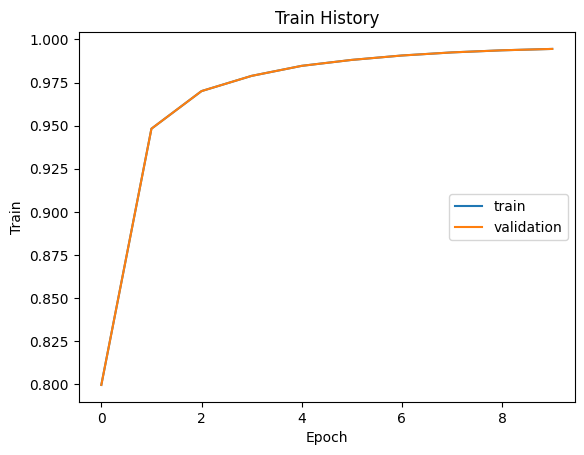

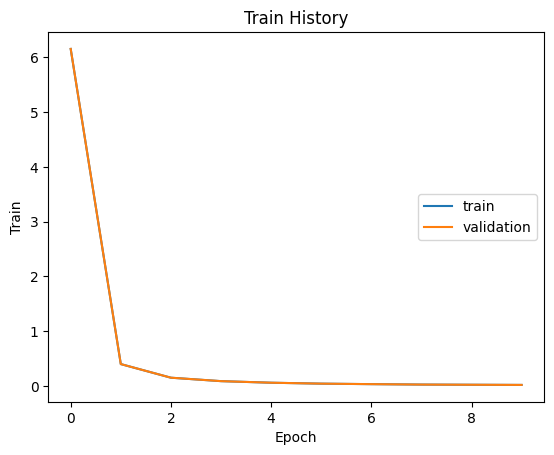

In [4]:
# 繪製準確率與損失圖
import matplotlib.pyplot as plt
import numpy as np

# 建立繪圖函式
def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel('Train')
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='center right')
    plt.show()

# 顯示準確率與損失
show_train_history(train_history, 'accuracy', 'accuracy')
show_train_history(train_history, 'loss', 'loss')

In [5]:
# 比較預測結果與正確答案
import pandas as pd

# 預測圖片
prediction = model.predict(test_data)

# 找出預測機率最高的數字
prediction_label=np.argmax(prediction,axis=1)

print(test_label.shape)

# 顯示混淆矩陣
pd.crosstab(test_label_original, prediction_label, rownames=['label'], colnames=['predict'])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
(10000, 10)


predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,971,0,3,0,1,0,4,0,1,0
1,0,1115,4,2,0,1,2,3,8,0
2,3,3,1002,5,0,0,1,9,9,0
3,0,0,1,995,0,6,0,4,3,1
4,2,0,1,1,962,0,3,1,1,11
5,2,0,0,7,0,878,2,0,3,0
6,6,2,0,0,2,3,942,0,3,0
7,0,2,8,1,0,0,0,1010,4,3
8,6,0,2,4,0,1,2,3,955,1
